In [1]:
import pandas as pd
from imageio.core import imopen
from matplotlib.pyplot import subplot
import seaborn as sns
from sympy import true

df_dw = pd.read_csv('C:/Users/rupom/PycharmProjects/JupyterProject/data/Bias_correction_ucl.csv')
df_dw


,station,Date,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,...,LDAPS_PPT2,LDAPS_PPT3,LDAPS_PPT4,lat,lon,DEM,Slope,Solar radiation,Next_Tmax,Next_Tmin
0,1.0,2013-06-30,28.7,21.4,58.255688,91.116364,28.074101,23.006936,6.818887,69.451805,...,0.000000,0.000000,0.000000,37.6046,126.991,212.3350,2.785000,5992.895996,29.1,21.2
1,2.0,2013-06-30,31.9,21.6,52.263397,90.604721,29.850689,24.035009,5.691890,51.937448,...,0.000000,0.000000,0.000000,37.6046,127.032,44.7624,0.514100,5869.312500,30.5,22.5
2,3.0,2013-06-30,31.6,23.3,48.690479,83.973587,30.091292,24.565633,6.138224,20.573050,...,0.000000,0.000000,0.000000,37.5776,127.058,33.3068,0.266100,5863.555664,31.1,23.9
3,4.0,2013-06-30,32.0,23.4,58.239788,96.483688,29.704629,23.326177,5.650050,65.727144,...,0.000000,0.000000,0.000000,37.6450,127.022,45.7160,2.534800,5856.964844,31.7,24.3
4,5.0,2013-06-30,31.4,21.9,56.174095,90.155128,29.113934,23.486480,5.735004,107.965535,...,0.000000,0.000000,0.000000,37.5507,127.135,35.0380,0.505500,5859.552246,31.2,22.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7747,23.0,2017-08-30,23.3,17.1,26.741310,78.869858,26.352081,18.775678,6.148918,72.058294,...,0.000000,0.000000,0.000000,37.5372,126.891,15.5876,0.155400,4443.313965,28.3,18.1
7748,24.0,2017-08-30,23.3,17.7,24.040634,77.294975,27.010193,18.733519,6.542819,47.241457,...,0.000000,0.000000,0.000000,37.5237,126.909,17.2956,0.222300,4438.373535,28.6,18.8
7749,25.0,2017-08-30,23.2,17.4,22.933014,77.243744,27.939516,18.522965,7.289264,9.090034,...,0.000000,0.000000,0.000000,37.5237,126.970,19.5844,0.271300,4451.345215,27.8,17.4
7750,NaN,NaN,20.0,11.3,19.794666,58.936283,17.624954,14.272646,2.882580,-13.603212,...,0.000000,0.000000,0.000000,37.4562,126.826,12.3700,0.098475,4329.520508,17.4,11.3


Location and time

station — one of 25 fixed weather stations around Seoul. Since each station sits in a different microclimate (elevation, coastal proximity, urban vs. rural), this variable captures location-specific effects that latitude/longitude alone might not fully explain.
Date — tells you the season and time trend. Summer months (this data is Jun–Aug across four years) will dominate the range, so day-of-year matters more than year-to-year drift.

Today's actual temperatures

Present_Tmax, Present_Tmin — what really happened today. Temperature tends to persist day-to-day (today's heat often carries into tomorrow), so these tell you the "inertia" baseline before any forecast model adjustment.

Humidity forecasts

LDAPS_RHmin, LDAPS_RHmax — forecast relative humidity range for tomorrow. Humidity has a strong physical link to diurnal temperature range: moist air holds heat and resists rapid heating/cooling, so high humidity tends to compress the gap between tomorrow's max and min. Low humidity (dry air) lets temperatures swing more widely.

The model's own temperature forecast

LDAPS_Tmax_lapse, LDAPS_Tmin_lapse — this is LDAPS's actual prediction for tomorrow's max/min, already adjusted for elevation via the lapse rate (temperature drops roughly 6.5°C per km of elevation gain). This is the "first guess" that the whole dataset exists to correct.

Wind

LDAPS_WS — forecast average wind speed. Wind mixes the atmosphere near the surface, which tends to smooth out temperature extremes — strong wind can prevent a location from getting as hot or as cold as it otherwise would, and it also affects how quickly moisture evaporates.

Latent heat flux

LDAPS_LH — energy used for evaporation/evapotranspiration rather than heating the air directly. Higher latent heat flux (e.g., over vegetation or moist soil) means more incoming energy goes into evaporating water instead of raising air temperature — a cooling effect on Tmax.

Cloud cover, split by time of day

LDAPS_CC1 (0–5h), CC2 (6–11h), CC3 (12–17h), CC4 (18–23h) — cloud cover in each 6-hour window. This split matters because clouds have opposite effects depending on when they occur: daytime cloud cover (CC2/CC3) blocks incoming solar radiation and suppresses Tmax, while nighttime cloud cover (CC4/CC1) traps outgoing longwave radiation and keeps Tmin higher (cloudy nights don't cool off as much as clear nights).

Precipitation, split by time of day

LDAPS_PPT1–PPT4 — forecast rainfall in each 6-hour window. Rain cools the surface through evaporation and associated cloud cover, and it's also a proxy for storm systems that disrupt the normal daily heating/cooling cycle. Which window has rain tells you when the disruption to the temperature curve happens.

Terrain

lat, lon — broad geographic position; small range here (all stations within a small area around Seoul) so effects will be subtle rather than dramatic.
DEM (elevation) — higher elevation stations run cooler independent of the lapse-rate adjustment already baked into the LDAPS forecast; useful for checking whether the model's lapse correction is fully capturing terrain effects or if elevation still explains leftover error.
Slope — steeper terrain affects sun exposure angle and cold-air drainage (cold air pools in valleys at night), which can shift local Tmin.

Solar radiation

Solar radiation — daily incoming solar energy. This is one of the most direct physical drivers of Tmax — more incoming sunlight, more surface heating, all else equal. It's the flip side of the daytime cloud cover variables.

Targets

Next_Tmax, Next_Tmin — the actual observed next-day max/min.

In [11]:
print(df_dw.shape)
print(df_dw.dtypes)

(7752, 25)
station             float64
Date                    str
Present_Tmax        float64
Present_Tmin        float64
LDAPS_RHmin         float64
LDAPS_RHmax         float64
LDAPS_Tmax_lapse    float64
LDAPS_Tmin_lapse    float64
LDAPS_WS            float64
LDAPS_LH            float64
LDAPS_CC1           float64
LDAPS_CC2           float64
LDAPS_CC3           float64
LDAPS_CC4           float64
LDAPS_PPT1          float64
LDAPS_PPT2          float64
LDAPS_PPT3          float64
LDAPS_PPT4          float64
lat                 float64
lon                 float64
DEM                 float64
Slope               float64
Solar radiation     float64
Next_Tmax           float64
Next_Tmin           float64
dtype: object


In [13]:
df_dw.isnull().sum()

station              2
Date                 2
Present_Tmax        70
Present_Tmin        70
LDAPS_RHmin         75
LDAPS_RHmax         75
LDAPS_Tmax_lapse    75
LDAPS_Tmin_lapse    75
LDAPS_WS            75
LDAPS_LH            75
LDAPS_CC1           75
LDAPS_CC2           75
LDAPS_CC3           75
LDAPS_CC4           75
LDAPS_PPT1          75
LDAPS_PPT2          75
LDAPS_PPT3          75
LDAPS_PPT4          75
lat                  0
lon                  0
DEM                  0
Slope                0
Solar radiation      0
Next_Tmax           27
Next_Tmin           27
dtype: int64

In [3]:
df_dw[["station","Present_Tmax"]]

,station,Present_Tmax
0,1.0,28.7
1,2.0,31.9
2,3.0,31.6
3,4.0,32.0
4,5.0,31.4
...,...,...
7747,23.0,23.3
7748,24.0,23.3
7749,25.0,23.2
7750,NaN,20.0


Checking for Outliers

<Axes: ylabel='Present_Tmax'>

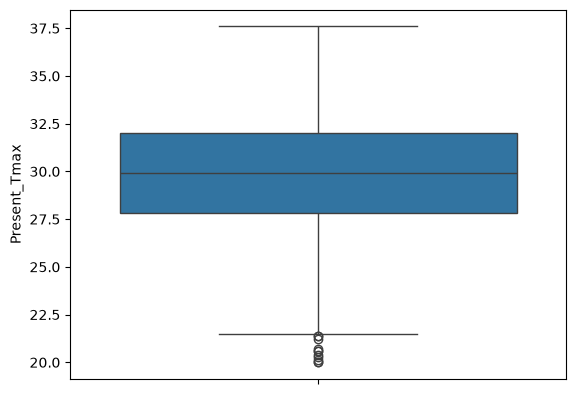

In [4]:
sns.boxplot(data=df_dw["Present_Tmax"])

<Axes: ylabel='Present_Tmin'>

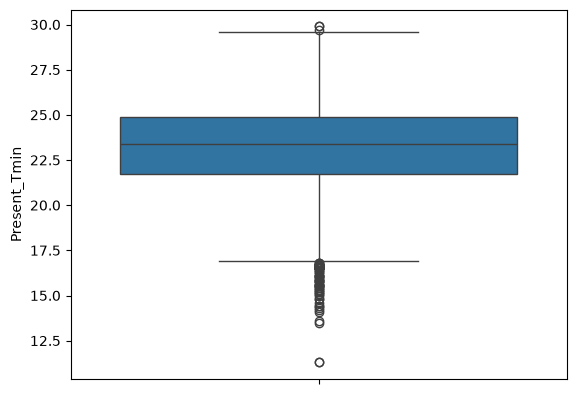

In [5]:
sns.boxplot(data=df_dw["Present_Tmin"])

<Axes: ylabel='LDAPS_RHmax'>

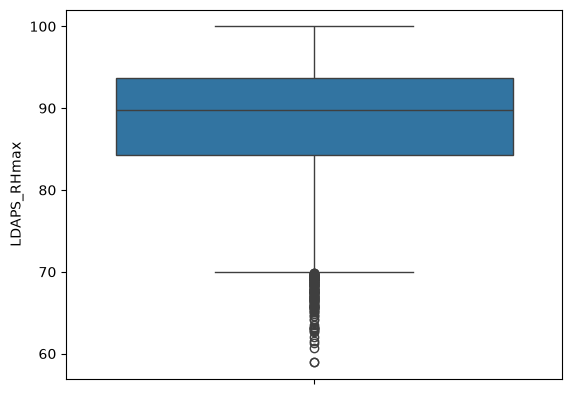

In [6]:
sns.boxplot(data=df_dw["LDAPS_RHmax"])

<Axes: xlabel='station', ylabel='Next_Tmax'>

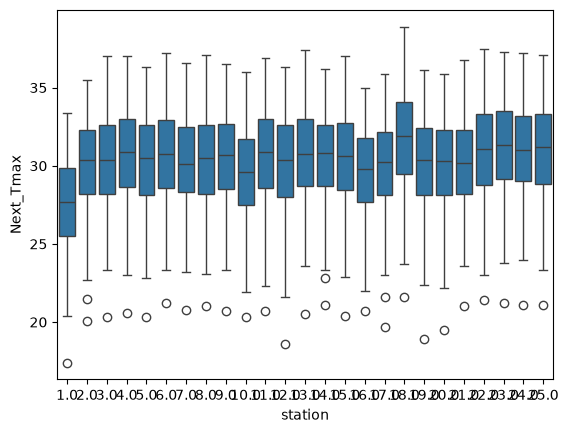

In [7]:
sns.boxplot(data=df_dw, x='station', y='Next_Tmax')

In [8]:
print(df_dw.shape)
print(df_dw.dtypes)


(7752, 25)
station             float64
Date                    str
Present_Tmax        float64
Present_Tmin        float64
LDAPS_RHmin         float64
LDAPS_RHmax         float64
LDAPS_Tmax_lapse    float64
LDAPS_Tmin_lapse    float64
LDAPS_WS            float64
LDAPS_LH            float64
LDAPS_CC1           float64
LDAPS_CC2           float64
LDAPS_CC3           float64
LDAPS_CC4           float64
LDAPS_PPT1          float64
LDAPS_PPT2          float64
LDAPS_PPT3          float64
LDAPS_PPT4          float64
lat                 float64
lon                 float64
DEM                 float64
Slope               float64
Solar radiation     float64
Next_Tmax           float64
Next_Tmin           float64
dtype: object


<Axes: xlabel='Solar radiation', ylabel='Present_Tmax'>

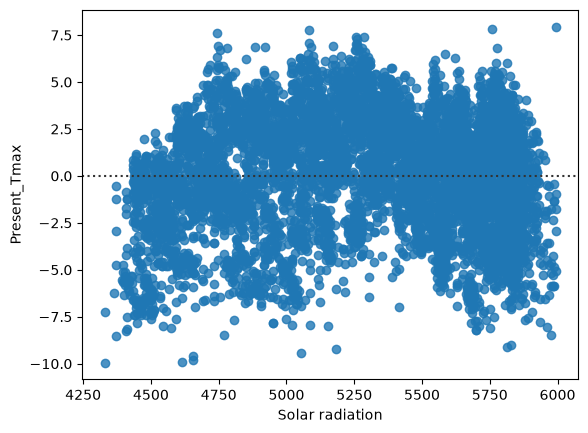

In [14]:
sns.residplot(data=df_dw, x="Solar radiation", y='Present_Tmax')

In [ ]:
T = df_dw[['Solar radiation','Present_Tmax']]